## 1. Settings

In [ ]:
import sys, subprocess, importlib.util
for pkg, mod in [('kagglehub', 'kagglehub'), ('pillow-heif', 'pillow_heif')]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import os, io, json, math, time, random, shutil, zipfile, hashlib, platform
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import PIL, sklearn, kagglehub
import pillow_heif
pillow_heif.register_heif_opener()          # iPhone HEIC photos open like JPEGs
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
BACKBONE = 'efficientnetv2b0'   # 'efficientnetv2b0' (recommended) | 'convnext_tiny' (stronger, ~3x slower) | 'mobilenetv2' (old)
IMAGE_SIZE = (224, 224)
CACHE_SIDE = 256                # train images are cached at 256 and randomly cropped to 224
BATCH_SIZE = 64
MAX_PER_CLASS = None            # v12 has 12,259 images (largest class 1,892); use them all. Class weights handle imbalance
NEAR_DUP_BITS = 4               # dHash distance counted as "same photo"
TEST_FOLDS, VAL_FOLDS = 5, 7    # 1/5 test, then 1/7 of the rest = validation

USE_WEB = True                  # add cleaned CC0 / CC-BY web photos
DOWNLOADS_PER_CLASS = 420       # raw downloads per class (dedupe + label check remove a share)
WEB_TEST_PER_CLASS, WEB_VAL_PER_CLASS, WEB_TRAIN_PER_CLASS = 40, 20, 150
WEB_TRAIN_REPEAT = 3            # web photos are rare and valuable: show each 3x per epoch
CLEAN_KAGGLE = True             # sklearn clean-up of Kaggle TRAIN images (test is never touched)
MAX_DROP_FRAC = 0.05            # drop at most 5% of any class
OUTLIER_FRAC = 0.02             # share of each class LocalOutlierFactor may flag
USE_OPENVERSE = False           # backup source, often slow
USE_BACKGROUNDS = True          # download floor/table photos for zoom-out augmentation
ZOOM_OUT_P = 0.35

REAL_TEST_ZIP = Path('/content/real_test.zip')
OWN_TRAIN_ZIP = Path('/content/own_train.zip')
OWN_TRAIN_REPEAT = 5
ORIGINAL_MODEL = Path('/content/original_garbage_cnn.keras')

HEAD_EPOCHS, FINE_EPOCHS = 4, 15
HEAD_LR, FINE_LR = 1e-3, 5e-5
LABEL_SMOOTHING = 0.1
PATIENCE = 4

OUT = Path('/content/garbage_reallife_results'); OUT.mkdir(parents=True, exist_ok=True)
CACHE = Path('/content/cache'); CACHE.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
GPU = bool(tf.config.list_physical_devices('GPU'))
if GPU:
    keras.mixed_precision.set_global_policy('mixed_float16')   # ~2x faster on T4; export is converted back to float32
else:
    print('WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU.')
print('TensorFlow', tf.__version__, '| Keras', keras.__version__, '| GPU:', GPU)

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: True


## 2. Helper functions
Web downloader (license filter: CC0 / public domain / CC BY only), dHash, and the training helpers.

In [ ]:
# STEP 4B helpers: collect extra CC0 / CC-BY / public-domain web images straight into Colab
import re
import io
import math
import time
import html
import random
import hashlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import requests
from PIL import Image, ImageOps

UA = {'User-Agent': 'garbage-cnn-student/1.0 (university class project; Google Colab)'}
COMMONS_API = 'https://commons.wikimedia.org/w/api.php'
OPENVERSE_API = 'https://api.openverse.org/v1/images/'
OPENVERSE_LICENSES = {'cc0': 'CC0', 'pdm': 'Public domain', 'by': 'CC BY'}
_openverse_failures = {'count': 0}


def license_ok(name):
    """True only for CC0, public domain and plain CC BY (no SA / NC / ND)."""
    n = (name or '').lower().replace('-', ' ').strip()
    words = n.split()
    if any(t in words for t in ('sa', 'nc', 'nd')):
        return False
    if n.startswith(('cc0', 'public domain', 'pdm')):
        return True
    return re.fullmatch(r'cc by( \d(\.\d)?)?', n) is not None


def clean_text(s, limit=200):
    s = re.sub(r'<[^>]+>', ' ', html.unescape(str(s or '')))
    return re.sub(r'\s+', ' ', s).strip()[:limit]


def get_json(url, params, tries=6, timeout=30):
    """GET JSON with backoff. Commons throttles bursts, so wait (Retry-After if given) and retry."""
    for attempt in range(tries):
        try:
            r = requests.get(url, params=params, headers=UA, timeout=timeout)
            if r.status_code == 429 or r.status_code >= 500:
                wait = r.headers.get('Retry-After', '')
                time.sleep(min(60, int(wait) if wait.isdigit() else 3 * 2 ** attempt))
                continue
            r.raise_for_status()
            d = r.json()
            if 'error' in d and d['error'].get('code') in ('ratelimited', 'maxlag'):
                time.sleep(min(60, 5 * 2 ** attempt))
                continue
            return d
        except (requests.RequestException, ValueError):
            time.sleep(min(30, 2 ** attempt))
    return None


def commons_candidates(query, label, limit, max_offset=1000):
    out, offset = [], 0
    while len(out) < limit and offset < max_offset:
        d = get_json(COMMONS_API, {
            'action': 'query', 'format': 'json', 'generator': 'search',
            'gsrsearch': f'filetype:bitmap {query}', 'gsrnamespace': 6, 'gsrlimit': 50,
            'gsroffset': offset, 'prop': 'imageinfo', 'iiprop': 'url|extmetadata|mime',
            'iiurlwidth': 480, 'iiextmetadatafilter': 'LicenseShortName|Artist|LicenseUrl'})
        if not d or 'query' not in d:
            break
        for pg in d['query']['pages'].values():
            ii = (pg.get('imageinfo') or [{}])[0]
            meta = ii.get('extmetadata', {})
            lic = meta.get('LicenseShortName', {}).get('value', '')
            if not license_ok(lic) or ii.get('mime') not in ('image/jpeg', 'image/png', 'image/webp'):
                continue
            out.append({
                'label': label, 'query': query, 'source': 'wikimedia_commons',
                'download_url': ii.get('thumburl') or ii.get('url'),
                'landing_url': ii.get('descriptionurl', ''), 'title': clean_text(pg.get('title')),
                'creator': clean_text(meta.get('Artist', {}).get('value', '')),
                'license': clean_text(lic), 'license_url': meta.get('LicenseUrl', {}).get('value', '')})
        if 'continue' not in d:
            break
        offset = int(d['continue']['gsroffset'])
        time.sleep(0.5)
    return out[:limit]


def openverse_candidates(query, label, limit, max_pages=2):
    """Backup source. Openverse often returns 504, so it switches itself off after 3 failures."""
    out = []
    for page in range(1, max_pages + 1):
        if _openverse_failures['count'] >= 3:
            break
        d = get_json(OPENVERSE_API, {'q': query, 'page_size': 20, 'page': page}, tries=2, timeout=20)
        if not d:
            _openverse_failures['count'] += 1
            break
        _openverse_failures['count'] = 0
        for r in d.get('results', []):
            lic = r.get('license')
            if lic not in OPENVERSE_LICENSES:
                continue
            name = OPENVERSE_LICENSES[lic]
            if lic == 'by' and r.get('license_version'):
                name += ' ' + r['license_version']
            out.append({
                'label': label, 'query': query, 'source': 'openverse_' + str(r.get('source', '')),
                'download_url': r.get('url'), 'landing_url': r.get('foreign_landing_url', ''),
                'title': clean_text(r.get('title')), 'creator': clean_text(r.get('creator')),
                'license': name, 'license_url': r.get('license_url', '')})
        if len(out) >= limit or page >= (d.get('page_count') or 0):
            break
    return out[:limit]


def dhash(im, size=8):
    g = im.convert('L').resize((size + 1, size), Image.Resampling.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int(''.join('1' if b else '0' for b in bits), 2)


def to_rgb(im):
    im = ImageOps.exif_transpose(im)
    if im.mode == 'P' or 'A' in im.getbands():
        im = im.convert('RGBA')
        bg = Image.new('RGB', im.size, (255, 255, 255))
        bg.paste(im, mask=im.getchannel('A'))
        return bg
    return im.convert('RGB')


def save_image_bytes(data, c, out_dir, min_side):
    """Decode, check size, save as JPEG. Returns a row dict or None."""
    with Image.open(io.BytesIO(data)) as im:
        im.load()
        rgb = to_rgb(im)
    if min(rgb.size) < min_side:
        return None
    rgb.thumbnail((640, 640))
    buf = io.BytesIO()
    rgb.save(buf, 'JPEG', quality=92)
    b = buf.getvalue()
    sha = hashlib.sha256(b).hexdigest()
    path = Path(out_dir) / c['label'] / f'{sha[:16]}.jpg'
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(b)
    return {**c, 'file_path': str(path), 'sha256': sha, 'dhash': dhash(rgb),
            'width': rgb.size[0], 'height': rgb.size[1]}


def fetch_image(c, out_dir, min_side=120, max_bytes=8_000_000):
    for attempt in range(3):
        try:
            r = requests.get(c['download_url'], headers=UA, timeout=25)
            if r.status_code == 429:
                time.sleep(3 * (attempt + 1))
                continue
            r.raise_for_status()
            if len(r.content) > max_bytes:
                return None
            return save_image_bytes(r.content, c, out_dir, min_side)
        except Exception:
            time.sleep(1)
    return None


def search_class(label, qs, per_query, use_openverse, workers=4, log=print):
    """Run the searches of one class in parallel (4 at a time is polite enough for Commons)."""
    def one(q):
        found = commons_candidates(q, label, per_query)
        if use_openverse:
            found += openverse_candidates(q, label, per_query // 2)
        return q, found
    results = {}
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for f in as_completed([ex.submit(one, q) for q in qs]):
            q, found = f.result()
            results[q] = found
            log(f'    searched {label}/{q!r}: {len(found)} licensed', flush=True)
    cands, seen = [], set()
    for q in qs:  # fixed order -> reproducible
        for c in results[q]:
            if c['download_url'] and c['download_url'] not in seen:
                seen.add(c['download_url'])
                cands.append(c)
    return cands


def collect(queries, out_dir, downloads_per_class, seed=42, workers=8, use_openverse=True, log=print):
    """Search + download class by class. Each finished class is saved, so a re-run resumes."""
    import pandas as pd
    rows = []
    for n, (label, qs) in enumerate(queries.items(), 1):
        done_csv = Path(out_dir) / f'_done_{label}.csv'
        if done_csv.exists():
            got = pd.read_csv(done_csv, dtype={'dhash': str}).to_dict('records')
            for g in got:
                g['dhash'] = int(g['dhash'])
            log(f'[{n}/{len(queries)}] {label:>11}: reused {len(got)} downloaded', flush=True)
            rows.extend(got)
            continue
        t0 = time.time()
        per_query = math.ceil(downloads_per_class * 1.5 / len(qs))
        cands = search_class(label, qs, per_query, use_openverse, log=log)
        random.Random(seed).shuffle(cands)
        cands = cands[:downloads_per_class]
        with ThreadPoolExecutor(max_workers=workers) as ex:
            futures = [ex.submit(fetch_image, c, out_dir) for c in cands]
            got = [f.result() for f in as_completed(futures)]
        got = sorted((g for g in got if g), key=lambda g: g['sha256'])
        if got:
            pd.DataFrame(got).assign(dhash=lambda d: d['dhash'].map(str)).to_csv(done_csv, index=False)
        log(f'[{n}/{len(queries)}] {label:>11}: {len(cands)} candidates -> {len(got)} downloaded '
            f'({time.time() - t0:.0f}s)', flush=True)
        rows.extend(got)
    return rows


def popcount64(x):
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(x)
    v = x.view(np.uint8).reshape(*x.shape, 8)
    return np.unpackbits(v, axis=-1).sum(axis=-1)


def min_hamming(a_hashes, b_hashes, chunk=512):
    """For each hash in a, the smallest Hamming distance to any hash in b."""
    a = np.asarray([np.uint64(h) for h in a_hashes], dtype=np.uint64)
    b = np.asarray([np.uint64(h) for h in b_hashes], dtype=np.uint64)
    if len(a) == 0 or len(b) == 0:
        return np.full(len(a), 64)
    out = np.empty(len(a), dtype=np.int64)
    for i in range(0, len(a), chunk):
        out[i:i + chunk] = popcount64(a[i:i + chunk, None] ^ b[None, :]).min(axis=1)
    return out


def dedupe_web(df, max_bits=4):
    """Drop exact/near duplicates inside the web set; drop whole groups whose labels disagree."""
    df = df.drop_duplicates('sha256').reset_index(drop=True)
    hashes = np.asarray([np.uint64(h) for h in df['dhash']], dtype=np.uint64)
    group = list(range(len(df)))
    for i in range(len(df) - 1):
        if group[i] != i:
            continue
        close = np.flatnonzero(popcount64(hashes[i] ^ hashes[i + 1:]) <= max_bits) + i + 1
        for j in close:
            if group[j] == j:
                group[j] = i
    df['group'] = group
    bad = df.groupby('group')['label'].nunique()
    df = df[~df['group'].isin(bad[bad > 1].index)]
    return df.drop_duplicates('group').drop(columns='group').reset_index(drop=True)

In [ ]:
# Helpers for the real-life garbage notebook (embedded into the notebook as one cell).
# Needs: numpy, PIL, tensorflow/keras and web_collect helpers (popcount64, to_rgb) defined before this cell.
import numpy as np
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageOps
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# ---------- near-duplicate groups (so copies of one photo never sit in both train and test) ----------
def near_dup_groups(hashes, labels, max_bits=4):
    """Union-find over dHash distance. Only same-label images are joined (cross-label hits are usually
    plain white backgrounds, not the same photo). Returns (group_id array, cross_label_pairs)."""
    h = np.asarray([np.uint64(x) for x in hashes], dtype=np.uint64)
    labels = np.asarray(labels)
    parent = np.arange(len(h))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    cross = 0
    for i in range(len(h) - 1):
        close = np.flatnonzero(popcount64(h[i] ^ h[i + 1:]) <= max_bits) + i + 1
        for j in close:
            if labels[j] != labels[i]:
                cross += 1
                continue
            ri, rj = find(i), find(j)
            if ri != rj:
                parent[rj] = ri
    return np.array([find(i) for i in range(len(h))]), cross


# ---------- image loading exactly like the web app: EXIF -> RGB -> bilinear stretch -> 0..255 float ----------
def load_like_app(path, size):
    with Image.open(path) as im:
        im = to_rgb(im)
        im = im.resize((size[1], size[0]), Image.Resampling.BILINEAR)
        return np.asarray(im, dtype=np.float32)


def predict_paths(model, paths, size, tta=False, chunk=256, workers=8):
    """Softmax probabilities for image files, in order. tta=True averages with the mirrored image."""
    out = []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for i in range(0, len(paths), chunk):
            x = np.stack(list(ex.map(lambda p: load_like_app(p, size), paths[i:i + chunk])))
            p = model.predict(x, verbose=0, batch_size=64)
            if tta:
                p = (p + model.predict(x[:, :, ::-1, :], verbose=0, batch_size=64)) / 2
            out.append(p)
    return np.concatenate(out) if out else np.zeros((0, model.output_shape[-1]))


# ---------- augmentation (runs in tf.data, images float 0..1 inside, 0..255 in/out) ----------
def random_resized_crop(img, size, area=(0.35, 1.0)):
    begin, crop, _ = tf.image.sample_distorted_bounding_box(
        tf.shape(img), tf.zeros([1, 0, 4]), min_object_covered=0.0,
        aspect_ratio_range=(0.75, 1.33), area_range=area, max_attempts=20,
        use_image_if_no_bounding_boxes=True)
    return tf.image.resize(tf.slice(img, begin, crop), size)


def synthetic_bg(size):
    c1, c2 = tf.random.uniform([1, 1, 3]), tf.random.uniform([1, 1, 3])
    t = tf.reshape(tf.linspace(0.0, 1.0, size[0]), [-1, 1, 1])
    bg = tf.broadcast_to(c1 * (1 - t) + c2 * t, (*size, 3))
    return tf.clip_by_value(bg + tf.random.normal((*size, 3), 0, 0.03), 0, 1)


def zoom_out(img, bg, size, scale=(0.45, 0.95)):
    """Shrink the photo and paste it on a background: object smaller in frame, with surroundings."""
    s = tf.random.uniform([], *scale)
    h = tf.cast(s * size[0], tf.int32)
    w = tf.minimum(tf.cast(s * size[1] * tf.random.uniform([], 0.85, 1.15), tf.int32), size[1])
    small = tf.image.resize(img, tf.stack([h, w]))
    oy = tf.random.uniform([], 0, size[0] - h + 1, tf.int32)
    ox = tf.random.uniform([], 0, size[1] - w + 1, tf.int32)
    pasted = tf.image.pad_to_bounding_box(small, oy, ox, size[0], size[1])
    mask = tf.image.pad_to_bounding_box(tf.ones(tf.stack([h, w, 1])), oy, ox, size[0], size[1])
    return pasted * mask + bg * (1 - mask)


def gaussian_blur(img, sigma):
    x = tf.range(-2.0, 3.0)
    g = tf.exp(-x ** 2 / (2 * sigma ** 2))
    g = g / tf.reduce_sum(g)
    kern = tf.tile((g[:, None] * g[None, :])[:, :, None, None], [1, 1, 3, 1])
    return tf.nn.depthwise_conv2d(img[None], kern, [1, 1, 1, 1], 'SAME')[0]


def make_augment(size, bg_bank=None, zoom_out_p=0.35):
    """Returns f(img_0_255, label) for one image. bg_bank: uint8 tensor [N, H, W, 3] or None."""
    def pick_bg():
        if bg_bank is None:
            return synthetic_bg(size)
        idx = tf.random.uniform([], 0, tf.shape(bg_bank)[0], tf.int32)
        real = tf.image.random_flip_left_right(tf.cast(bg_bank[idx], tf.float32) / 255.0)
        return tf.cond(tf.random.uniform([]) < 0.7, lambda: real, lambda: synthetic_bg(size))

    def chance(p):
        return tf.random.uniform([]) < p

    def augment(img, label):
        img = img / 255.0
        img = tf.image.random_flip_left_right(img)
        img = tf.cond(chance(zoom_out_p), lambda: zoom_out(img, pick_bg(), size), lambda: img)
        img = tf.image.random_brightness(img, 0.2)
        img = tf.image.random_contrast(img, 0.7, 1.3)
        img = tf.image.random_saturation(img, 0.6, 1.4)
        img = tf.image.random_hue(img, 0.04)
        img = tf.clip_by_value(img, 0, 1)
        img = tf.cond(chance(0.05), lambda: tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(img)), lambda: img)
        img = tf.cond(chance(0.2), lambda: gaussian_blur(img, tf.random.uniform([], 0.5, 1.5)), lambda: img)
        img = tf.cond(chance(0.2), lambda: tf.clip_by_value(
            img + tf.random.normal(tf.shape(img), 0, tf.random.uniform([], 0.01, 0.04)), 0, 1), lambda: img)
        img = tf.cond(chance(0.3), lambda: tf.image.random_jpeg_quality(img, 40, 95), lambda: img)
        img = tf.reshape(img, (*size, 3))
        return img * 255.0, label
    return augment


# ---------- model ----------
def build_model(backbone, size, n_classes, weights='imagenet', dropout=0.3):
    """Input: RGB 0..255 (same contract as the web app). Returns (model, base)."""
    shape = (*size, 3)
    inputs = keras.Input(shape=shape, name='rgb_0_255')
    if backbone == 'efficientnetv2b0':
        base = keras.applications.EfficientNetV2B0(include_top=False, weights=weights, input_shape=shape,
                                                   include_preprocessing=True)
        x = inputs
    elif backbone == 'convnext_tiny':
        base = keras.applications.ConvNeXtTiny(include_top=False, weights=weights, input_shape=shape,
                                               include_preprocessing=True)
        x = inputs
    elif backbone == 'mobilenetv2':
        base = keras.applications.MobileNetV2(include_top=False, weights=weights, input_shape=shape)
        x = layers.Rescaling(1. / 127.5, offset=-1, name='mobilenet_scaling')(inputs)
    else:
        raise ValueError(f'unknown backbone {backbone!r}')
    x = base(x, training=False)  # BatchNorm stays in inference mode even when fine-tuning
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(dropout, name='dropout')(x)
    outputs = layers.Dense(n_classes, activation='softmax', dtype='float32', name='garbage_category')(x)
    return keras.Model(inputs, outputs, name=f'garbage_{backbone}'), base


# ---------- data cleaning with sklearn (features from the same ImageNet backbone, no outside model) ----------
def extract_features(paths, size, backbone, chunk=256, workers=8):
    """Frozen ImageNet backbone -> one 1280-number vector per image (no training)."""
    m, _ = build_model(backbone, size, 2)
    feat = keras.Model(m.input, m.get_layer('gap').output)
    out = []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for i in range(0, len(paths), chunk):
            x = np.stack(list(ex.map(lambda p: load_like_app(p, size), paths[i:i + chunk])))
            out.append(np.asarray(feat.predict(x, verbose=0, batch_size=64), dtype=np.float32))
    return np.concatenate(out)


def make_sklearn_clf(seed=42):
    """Scale -> PCA 256 -> logistic regression. Fast, and good enough to judge labels."""
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    return make_pipeline(StandardScaler(), PCA(256, random_state=seed),
                         LogisticRegression(C=0.5, max_iter=3000))


def out_of_fold_probs(X, y, groups, folds=5, seed=42):
    """Every image is predicted by a classifier that never saw it (or its near-duplicates)."""
    from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
    cv = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed)
    return cross_val_predict(make_sklearn_clf(seed), X, y, groups=groups, cv=cv, method='predict_proba', n_jobs=-1)


def find_label_issues(P, y):
    """Confident-learning rule: class j's threshold = average confidence for j on images labelled j.
    Flag an image when another class clears its threshold AND beats the given label."""
    n, k = P.shape
    thr = np.array([P[y == j, j].mean() for j in range(k)])
    above = P >= thr[None, :]
    above[np.arange(n), y] = False
    best_other = np.where(above, P, -1).argmax(1)
    flagged = above.any(1) & (P[np.arange(n), best_other] > P[np.arange(n), y])
    margin = P[np.arange(n), best_other] - P[np.arange(n), y]
    return flagged, best_other, margin


def find_outliers(X, y, contamination=0.03, seed=42):
    """Per class LocalOutlierFactor: images that look unlike the rest of their class (collages, junk, odd crops).
    Returns (flag, score) where a higher score means more unusual."""
    from sklearn.decomposition import PCA
    from sklearn.neighbors import LocalOutlierFactor
    Z = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
    Z = PCA(64, random_state=seed).fit_transform(Z)
    flag, score = np.zeros(len(y), bool), np.zeros(len(y))
    for j in np.unique(y):
        idx = np.flatnonzero(y == j)
        lof = LocalOutlierFactor(n_neighbors=min(20, len(idx) - 1), contamination=contamination)
        flag[idx] = lof.fit_predict(Z[idx]) == -1
        score[idx] = -lof.negative_outlier_factor_
    return flag, score


def cap_per_class(flag, y, score, max_frac):
    """Never drop more than max_frac of any class; keep the most suspicious ones."""
    keep_flag = np.zeros_like(flag)
    for j in np.unique(y):
        idx = np.flatnonzero((y == j) & flag)
        limit = int(max_frac * (y == j).sum())
        keep_flag[idx[np.argsort(-score[idx])][:limit]] = True
    return keep_flag


# ---------- confidence calibration ----------
def apply_temperature(probs, t):
    z = np.log(np.clip(probs, 1e-7, 1.0)) / t
    z -= z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def fit_temperature(probs, y):
    """Temperature that minimises validation NLL (coarse grid, then a fine grid around the best)."""
    def nll(t):
        p = apply_temperature(probs, t)
        return -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))
    grid = np.linspace(0.3, 5.0, 48)
    best = grid[np.argmin([nll(t) for t in grid])]
    fine = np.linspace(max(0.3, best - 0.1), best + 0.1, 41)
    return float(fine[np.argmin([nll(t) for t in fine])])


def coverage_table(probs, y, thresholds=(0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)):
    """If the app says 'not sure' below a threshold: how many photos get an answer, and how many are right."""
    conf, pred = probs.max(1), probs.argmax(1)
    rows = []
    for t in thresholds:
        keep = conf >= t
        rows.append({'threshold': t, 'answered': float(keep.mean()),
                     'accuracy_when_answered': float((pred[keep] == y[keep]).mean()) if keep.any() else float('nan')})
    return rows

## 3. Kaggle dataset

In [ ]:
DATASET = 'sumn2u/garbage-classification-v2/versions/12'
DATA_DIR = Path(kagglehub.dataset_download(DATASET)) / 'original'
assert DATA_DIR.is_dir(), DATA_DIR
classes = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
assert len(classes) == 10, classes
label_to_id = {c: i for i, c in enumerate(classes)}
EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.heic', '.heif'}

rng = np.random.default_rng(SEED)
rows = []
for c in classes:
    paths = sorted(p for p in (DATA_DIR / c).iterdir() if p.suffix.lower() in EXTS)
    if MAX_PER_CLASS and len(paths) > MAX_PER_CLASS:
        paths = [paths[i] for i in sorted(rng.choice(len(paths), MAX_PER_CLASS, replace=False))]
    rows += [{'file_path': str(p), 'label': c, 'source': 'kaggle'} for p in paths]
kaggle = pd.DataFrame(rows)
print(kaggle['label'].value_counts().sort_index().to_dict(), '| total', len(kaggle))

Using Colab cache for faster access to the 'garbage-classification-v2' dataset.
{'battery': 756, 'biological': 699, 'cardboard': 1411, 'clothes': 1892, 'glass': 1736, 'metal': 930, 'paper': 1336, 'plastic': 1597, 'shoes': 1449, 'trash': 453} | total 12259


## 4. Cache images + find near-duplicates

kaggle: cached 12259 images in 223s
Near-duplicate groups: 124 groups hold 511 images (largest group 80). Cross-label look-alike pairs ignored: 1251


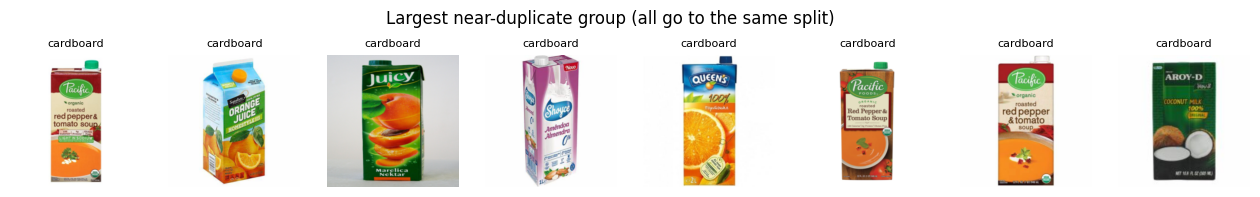

In [ ]:
def cache_image(src, key):
    """Returns (train_jpg, eval_png, dhash) or None if the file is broken."""
    tr, ev = CACHE / 'train' / f'{key}.jpg', CACHE / 'eval' / f'{key}.png'
    try:
        with Image.open(src) as im:
            im.load()
            rgb = to_rgb(im)
        h = dhash(rgb)
        if not (tr.exists() and ev.exists()):
            rgb.resize((CACHE_SIDE, CACHE_SIDE), Image.Resampling.BILINEAR).save(tr, quality=95)
            rgb.resize((IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR).save(ev)
        return str(tr), str(ev), h
    except Exception as e:
        print('skip broken file:', src, type(e).__name__)
        return None

def cache_frame(df, prefix):
    (CACHE / 'train').mkdir(exist_ok=True); (CACHE / 'eval').mkdir(exist_ok=True)
    keys = [f'{prefix}_{hashlib.md5(p.encode()).hexdigest()[:16]}' for p in df['file_path']]
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=16) as ex:
        res = list(ex.map(cache_image, df['file_path'], keys))
    ok = [r is not None for r in res]
    df = df[ok].copy()
    df['train_path'], df['eval_path'], df['dhash'] = zip(*[r for r in res if r is not None])
    print(f'{prefix}: cached {len(df)} images in {time.time() - t0:.0f}s')
    return df.reset_index(drop=True)

kaggle = cache_frame(kaggle, 'kaggle')
kaggle['group'], cross = near_dup_groups(kaggle['dhash'], kaggle['label'], NEAR_DUP_BITS)
sizes = kaggle['group'].value_counts()
print(f'Near-duplicate groups: {int((sizes > 1).sum())} groups hold {int(sizes[sizes > 1].sum())} images '
      f'(largest group {int(sizes.max())}). Cross-label look-alike pairs ignored: {cross}')

# Show the biggest duplicate group so you can see what "near-duplicate" means here
big = kaggle[kaggle['group'] == sizes.index[0]].head(8)
fig, axes = plt.subplots(1, len(big), figsize=(2 * len(big), 2.3))
for ax, (_, r) in zip(np.atleast_1d(axes), big.iterrows()):
    ax.imshow(Image.open(r['eval_path'])); ax.set_title(r['label'], fontsize=8); ax.axis('off')
plt.suptitle('Largest near-duplicate group (all go to the same split)'); plt.show()

## 5. Grouped split: train / validation / Kaggle test

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=TEST_FOLDS, shuffle=True, random_state=SEED)
tr_i, te_i = next(sgkf.split(kaggle, kaggle['label'], kaggle['group']))
pool, k_test = kaggle.iloc[tr_i].reset_index(drop=True), kaggle.iloc[te_i].reset_index(drop=True)
sgkf2 = StratifiedGroupKFold(n_splits=VAL_FOLDS, shuffle=True, random_state=SEED)
tr_i, va_i = next(sgkf2.split(pool, pool['label'], pool['group']))
k_train, k_val = pool.iloc[tr_i].reset_index(drop=True), pool.iloc[va_i].reset_index(drop=True)
assert not set(k_train['group']) & set(k_test['group']) and not set(k_train['group']) & set(k_val['group'])
print('Kaggle train / val / test:', len(k_train), len(k_val), len(k_test))
display(pd.DataFrame({'train': k_train['label'].value_counts(), 'val': k_val['label'].value_counts(),
                      'test': k_test['label'].value_counts()}).sort_index())

Kaggle train / val / test: 8413 1396 2450


,train,val,test
label,,,
battery,528,83,145
biological,490,83,126
cardboard,932,155,324
clothes,1290,229,373
glass,1198,199,339
metal,638,107,185
paper,927,147,262
plastic,1102,178,317
shoes,995,164,290


## 5B. Clean the Kaggle training images with sklearn

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Features (8413, 1280) in 81s
sklearn out-of-fold accuracy (frozen features, no fine-tuning): 90.8%


,suspect_label,outlier,dropped,total
label,,,,
battery,17,11,24,528
biological,10,10,19,490
cardboard,52,19,46,932
clothes,9,26,33,1290
glass,91,24,59,1198
metal,60,13,31,638
paper,71,19,46,927
plastic,88,23,55,1102
shoes,10,20,28,995


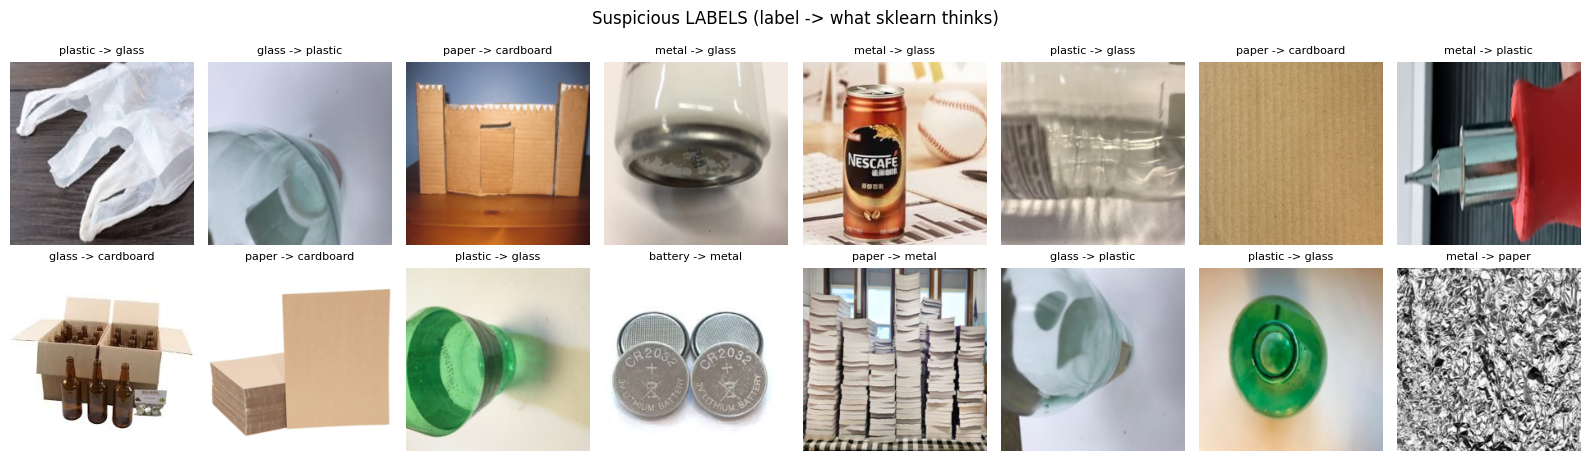

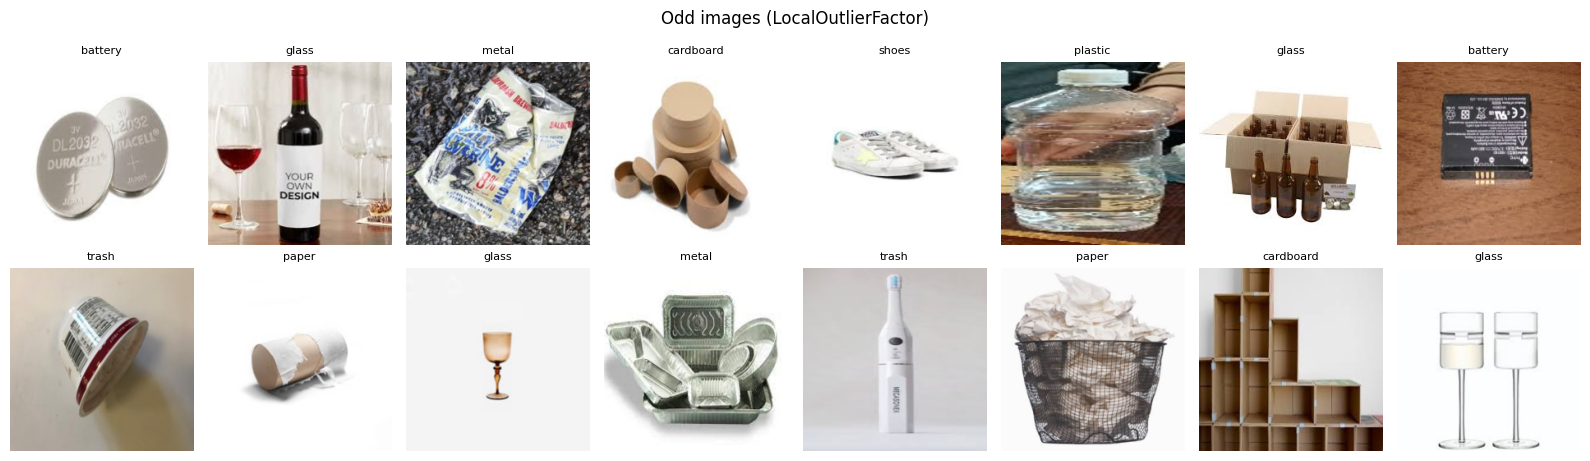

Kaggle train after clean-up: 8057 (dropped 356)


In [ ]:
from sklearn.metrics import accuracy_score as _acc
t0 = time.time()
X_tr = extract_features(k_train['eval_path'].tolist(), IMAGE_SIZE, BACKBONE)
y_tr = k_train['label'].map(label_to_id).to_numpy()
print(f'Features {X_tr.shape} in {time.time() - t0:.0f}s')

P_oof = out_of_fold_probs(X_tr, y_tr, k_train['group'].to_numpy(), folds=5, seed=SEED)
print('sklearn out-of-fold accuracy (frozen features, no fine-tuning):', f'{_acc(y_tr, P_oof.argmax(1)):.1%}')
lab_flag, other, margin = find_label_issues(P_oof, y_tr)
out_flag, out_score = find_outliers(X_tr, y_tr, contamination=OUTLIER_FRAC, seed=SEED)
k_train['suspect_label'] = lab_flag
k_train['suggested'] = [classes[j] for j in other]
k_train['outlier'] = out_flag

# rank: label issues by margin, outliers by LOF score; then cap per class
score = np.where(lab_flag, 10 + margin, np.where(out_flag, out_score, 0.0))
drop = cap_per_class(lab_flag | out_flag, y_tr, score, MAX_DROP_FRAC) if CLEAN_KAGGLE else np.zeros(len(y_tr), bool)
k_train['dropped'] = drop
display(k_train.groupby('label')[['suspect_label', 'outlier', 'dropped']].sum().assign(total=k_train['label'].value_counts()))

def grid(df, title, note):
    df = df.head(16)
    if not len(df): print('nothing to show for', title); return
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), df.iterrows()):
        ax.imshow(Image.open(r['eval_path'])); ax.set_title(note(r), fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

order = np.argsort(-margin)
grid(k_train.iloc[order][k_train.iloc[order]['suspect_label']], 'Suspicious LABELS (label -> what sklearn thinks)',
     lambda r: f"{r['label']} -> {r['suggested']}")
grid(k_train.iloc[np.argsort(-out_score)][lambda d: d['outlier']], 'Odd images (LocalOutlierFactor)', lambda r: r['label'])
k_train.loc[drop, ['file_path', 'label', 'suggested', 'suspect_label', 'outlier']].to_csv(OUT / 'dropped_kaggle_images.csv', index=False)
k_train = k_train[~k_train['dropped']].reset_index(drop=True)
print('Kaggle train after clean-up:', len(k_train), f'(dropped {int(drop.sum())})')

# Classifier on the cleaned train set, reused to check web photos in step 6
X_tr, y_tr = X_tr[~drop], y_tr[~drop]
web_checker = make_sklearn_clf(SEED).fit(X_tr, y_tr)

## 6. Web photos (real-life style) – download, dedupe, sklearn label check

In [ ]:
QUERIES = {
    'battery':    ['used battery', 'AA battery', 'old batteries', 'lithium battery', 'button cell battery', 'batteries recycling'],
    'biological': ['food waste', 'banana peel', 'apple core', 'vegetable scraps', 'compost food scraps', 'rotten fruit', 'eggshells'],
    'cardboard':  ['cardboard box', 'corrugated cardboard', 'flattened cardboard', 'cardboard packaging', 'pizza box'],
    'clothes':    ['old clothes', 't-shirt', 'jeans', 'used clothing', 'sweater', 'pile of clothes'],
    'glass':      ['glass bottle', 'glass jar', 'wine bottle', 'empty glass bottles', 'beer bottle'],
    'metal':      ['aluminium can', 'tin can', 'soda can', 'crushed can', 'scrap metal', 'food can'],
    'paper':      ['newspaper', 'crumpled paper', 'waste paper', 'office paper', 'magazines', 'paper bag'],
    'plastic':    ['plastic bottle', 'plastic bag', 'plastic container', 'plastic packaging', 'plastic cup', 'plastic waste'],
    'shoes':      ['old shoes', 'sneakers', 'pair of shoes', 'boots', 'sandals', 'worn shoes'],
    'trash':      ['trash', 'garbage', 'litter', 'garbage bag', 'food wrapper', 'cigarette butts', 'chip bag'],
}
assert sorted(QUERIES) == classes
WEB_DIR = Path('/content/web'); WEB_DIR.mkdir(exist_ok=True)
web_train = web_val = web_test = pd.DataFrame(columns=['file_path', 'label', 'source'])
credits = pd.DataFrame()
if USE_WEB:
    web_raw = pd.DataFrame(collect(QUERIES, WEB_DIR, DOWNLOADS_PER_CLASS, seed=SEED, use_openverse=USE_OPENVERSE))
    assert web_raw['license'].map(license_ok).all()
    web = dedupe_web(web_raw, max_bits=NEAR_DUP_BITS)
    dist = min_hamming(web['dhash'].tolist(), kaggle['dhash'].tolist())
    web = web[dist > NEAR_DUP_BITS].reset_index(drop=True)
    print(f'Web: {len(web_raw)} downloaded -> {len(web)} after removing duplicates / Kaggle look-alikes')

    searched battery/'old batteries': 105 licensed
    searched battery/'lithium battery': 105 licensed
    searched battery/'AA battery': 105 licensed
    searched battery/'used battery': 105 licensed
    searched battery/'batteries recycling': 89 licensed
    searched battery/'button cell battery': 61 licensed
[1/10]     battery: 420 candidates -> 395 downloaded (343s)
    searched biological/'vegetable scraps': 2 licensed
    searched biological/'food waste': 90 licensed
    searched biological/'compost food scraps': 0 licensed
    searched biological/'banana peel': 90 licensed
    searched biological/'rotten fruit': 59 licensed
    searched biological/'eggshells': 90 licensed
    searched biological/'apple core': 90 licensed
[2/10]  biological: 420 candidates -> 390 downloaded (310s)
    searched cardboard/'flattened cardboard': 19 licensed
    searched cardboard/'cardboard packaging': 126 licensed
    searched cardboard/'corrugated cardboard': 126 licensed
    searched cardboard/'

Kept per class: {'battery': 117, 'biological': 192, 'cardboard': 126, 'clothes': 169, 'glass': 270, 'metal': 161, 'paper': 224, 'plastic': 132, 'shoes': 245, 'trash': 58} | rejected 2052
Web train / val / test: 1019 188 378


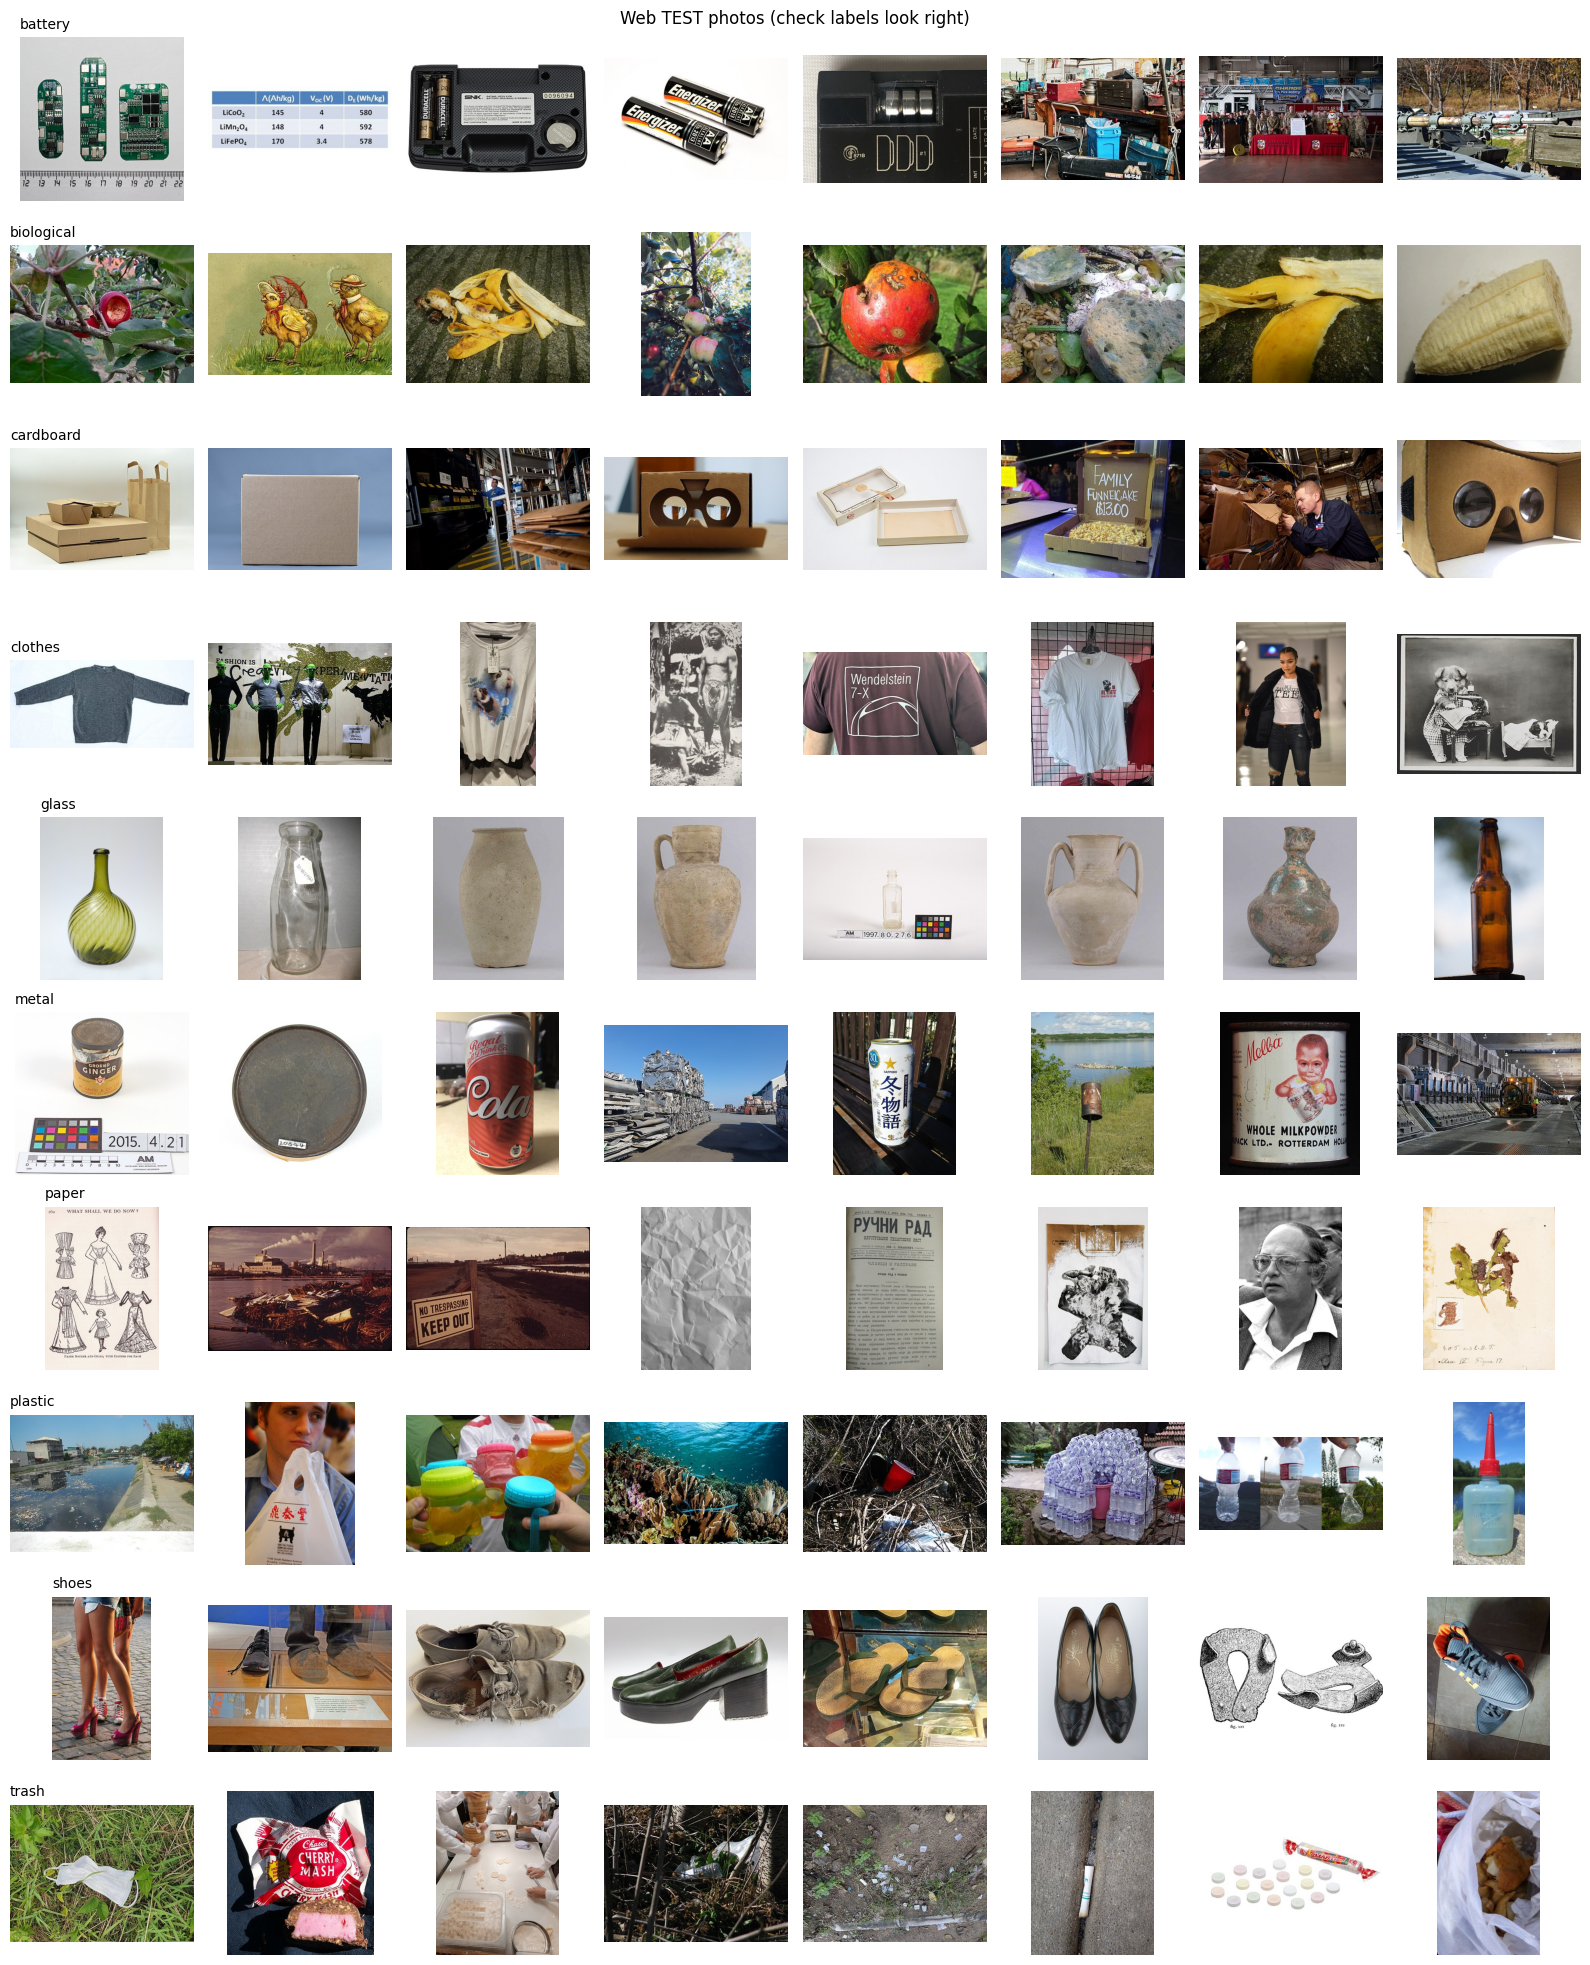

In [ ]:
# sklearn check: keep a web photo only if its label is in the classifier's top 2 with at least 15%.
# Lenient on purpose: web photos SHOULD look different from Kaggle, we only want to drop clear junk / wrong labels.
if USE_WEB:
    X_web = extract_features(web['file_path'].tolist(), IMAGE_SIZE, BACKBONE)
    P_web = web_checker.predict_proba(X_web)
    own = web['label'].map(label_to_id).to_numpy()
    top2 = np.argsort(-P_web, axis=1)[:, :2]
    web['label_ok'] = (top2 == own[:, None]).any(1) & (P_web[np.arange(len(web)), own] >= 0.15)
    web['checker_pred'] = [classes[j] for j in P_web.argmax(1)]
    clean = web[web['label_ok']].sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    print('Kept per class:', clean['label'].value_counts().sort_index().to_dict(), f'| rejected {int((~web.label_ok).sum())}')

    # Split per class: test first (so every class gets a test set), then val, then train
    parts = {'test': [], 'val': [], 'train': []}
    for c, g in clean.groupby('label'):
        n_te = min(WEB_TEST_PER_CLASS, len(g) // 3)
        n_va = min(WEB_VAL_PER_CLASS, (len(g) - n_te) // 4)
        parts['test'].append(g.iloc[:n_te]); parts['val'].append(g.iloc[n_te:n_te + n_va])
        parts['train'].append(g.iloc[n_te + n_va:n_te + n_va + WEB_TRAIN_PER_CLASS])
    web_test, web_val, web_train = (pd.concat(parts[k]).assign(source='web').reset_index(drop=True)
                                    for k in ('test', 'val', 'train'))
    credits = pd.concat([web_train.assign(split='train'), web_val.assign(split='val'), web_test.assign(split='web_test')])
    credits = credits[['label', 'split', 'title', 'creator', 'license', 'license_url', 'landing_url', 'source', 'query']]
    print('Web train / val / test:', len(web_train), len(web_val), len(web_test))

    fig, axes = plt.subplots(len(classes), 8, figsize=(16, 2 * len(classes)))
    for r, c in enumerate(classes):
        s = web_test[web_test['label'] == c]['file_path'].head(8).tolist()
        for k, ax in enumerate(axes[r]):
            ax.axis('off')
            if k < len(s): ax.imshow(Image.open(s[k]).convert('RGB'))
            if k == 0: ax.set_title(c, loc='left', fontsize=10)
    plt.suptitle('Web TEST photos (check labels look right)'); plt.tight_layout(); plt.show()

## 7. Our own photos (optional) + background photos for augmentation

In [ ]:
def read_class_zip(zip_path, name):
    """Unzip; find folders named like the classes at any depth. Returns DataFrame(file_path, label)."""
    if not zip_path.exists():
        print(f'{zip_path.name} not found -> skipped'); return pd.DataFrame(columns=['file_path', 'label', 'source'])
    dest = Path('/content') / name
    shutil.rmtree(dest, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as z: z.extractall(dest)
    rows = []
    for p in dest.rglob('*'):
        if p.is_file() and p.suffix.lower() in EXTS and not p.name.startswith('.') and '__MACOSX' not in p.parts:
            lab = next((q.lower() for q in reversed(p.parent.relative_to(dest).parts) if q.lower() in label_to_id), None)
            if lab: rows.append({'file_path': str(p), 'label': lab, 'source': name})
            else: print('no class folder for', p.relative_to(dest))
    df = pd.DataFrame(rows, columns=['file_path', 'label', 'source'])
    print(f'{name}: {len(df)} photos', df['label'].value_counts().sort_index().to_dict())
    return df

real_test = read_class_zip(REAL_TEST_ZIP, 'real_test')
own_train = read_class_zip(OWN_TRAIN_ZIP, 'own_train')
if len(real_test) and len(own_train):
    d = min_hamming([dhash(to_rgb(Image.open(p))) for p in own_train['file_path']],
                    [dhash(to_rgb(Image.open(p))) for p in real_test['file_path']])
    if (d <= NEAR_DUP_BITS).any():
        print(f'Removing {(d <= NEAR_DUP_BITS).sum()} own_train photos that are near-copies of real_test photos')
        own_train = own_train[d > NEAR_DUP_BITS].reset_index(drop=True)

bg_bank = None
if USE_BACKGROUNDS:
    BG_QUERIES = {'background': ['wooden table top', 'concrete floor', 'tiled floor', 'carpet texture', 'kitchen counter',
                                 'asphalt texture', 'lawn grass texture', 'desk surface', 'sidewalk pavement', 'linoleum floor']}
    try:
        bg_rows = collect(BG_QUERIES, Path('/content/backgrounds'), 200, seed=SEED, use_openverse=USE_OPENVERSE)
        bgs = [np.asarray(to_rgb(Image.open(r['file_path'])).resize((IMAGE_SIZE[1], IMAGE_SIZE[0])), np.uint8) for r in bg_rows]
        if len(bgs) >= 20:
            bg_bank = tf.constant(np.stack(bgs))
            print('Background photos:', len(bgs))
    except Exception as e:
        print('Background download failed, using synthetic backgrounds only:', e)

real_test.zip not found -> skipped
own_train.zip not found -> skipped
    searched background/'wooden table top': 30 licensed
    searched background/'carpet texture': 30 licensed
    searched background/'concrete floor': 30 licensed
    searched background/'asphalt texture': 30 licensed
    searched background/'lawn grass texture': 30 licensed
    searched background/'desk surface': 30 licensed
    searched background/'tiled floor': 30 licensed
    searched background/'linoleum floor': 30 licensed
    searched background/'kitchen counter': 30 licensed
    searched background/'sidewalk pavement': 30 licensed
[1/1]  background: 200 candidates -> 192 downloaded (100s)
Background photos: 192


## 8. Build the training data

webtr: cached 1019 images in 21s
webva: cached 188 images in 5s
webte: cached 378 images in 7s
Train rows (with repeats): 11114 | val: 1584


source,kaggle,web
label,,
battery,504,177
biological,471,396
cardboard,886,198
clothes,1257,327
glass,1139,450
metal,607,303
paper,881,450
plastic,1047,216
shoes,967,450


Class weights: {'battery': 1.63, 'biological': 1.28, 'cardboard': 1.03, 'clothes': 0.7, 'glass': 0.7, 'metal': 1.22, 'paper': 0.84, 'plastic': 0.88, 'shoes': 0.78, 'trash': 2.86}


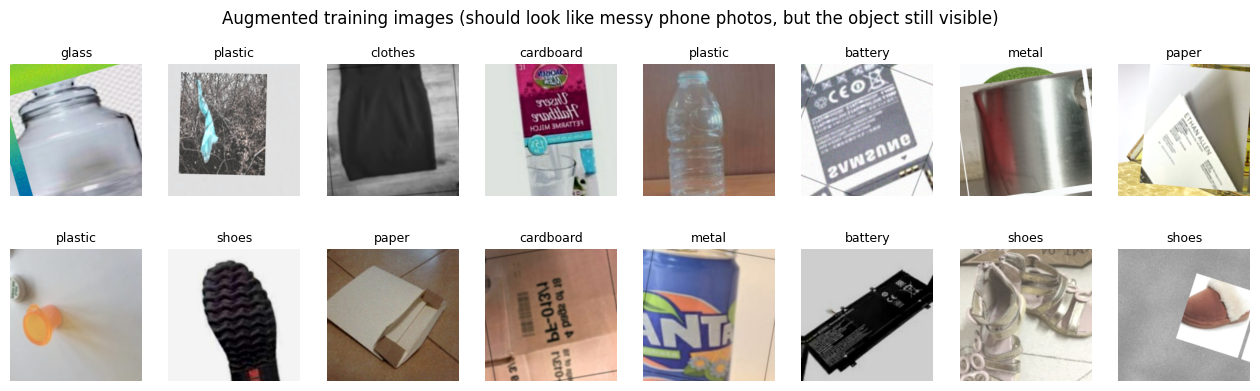

In [ ]:
to_cache = [(web_train, 'webtr'), (web_val, 'webva'), (web_test, 'webte'), (own_train, 'own'), (real_test, 'real')]
web_train, web_val, web_test, own_train, real_test = [cache_frame(d, p) if len(d) else d.assign(train_path=[], eval_path=[])
                                                      for d, p in to_cache]

train_df = pd.concat([k_train] + [web_train] * WEB_TRAIN_REPEAT + [own_train] * OWN_TRAIN_REPEAT, ignore_index=True)
val_df = pd.concat([k_val, web_val], ignore_index=True)       # model selection also rewards web-style photos
for d in (train_df, val_df):
    d['label_id'] = d['label'].map(label_to_id).astype('int32')
print('Train rows (with repeats):', len(train_df), '| val:', len(val_df))
display(pd.crosstab(train_df['label'], train_df['source']))

counts = train_df['label_id'].value_counts()
class_weight = {int(i): float(len(train_df) / (len(classes) * n)) for i, n in counts.items()}
print('Class weights:', {classes[k]: round(v, 2) for k, v in sorted(class_weight.items())})

augment = make_augment(IMAGE_SIZE, bg_bank, ZOOM_OUT_P)
rotate = layers.RandomRotation(0.06, fill_mode='reflect', dtype='float32', name='rotate')

def read_train(path, y):
    img = tf.cast(tf.io.decode_jpeg(tf.io.read_file(path), channels=3), tf.float32)
    return random_resized_crop(img, IMAGE_SIZE), y

def read_eval(path, y):
    img = tf.cast(tf.io.decode_png(tf.io.read_file(path), channels=3), tf.float32)
    return tf.reshape(img, (*IMAGE_SIZE, 3)), y

def make_ds(df, train):
    y = keras.utils.to_categorical(df['label_id'], len(classes)).astype('float32')
    ds = tf.data.Dataset.from_tensor_slices((df['train_path' if train else 'eval_path'].to_numpy(str), y))
    if train:
        ds = (ds.shuffle(len(df), seed=SEED).map(read_train, tf.data.AUTOTUNE).map(augment, tf.data.AUTOTUNE)
                .batch(BATCH_SIZE, drop_remainder=True).map(lambda x, y: (rotate(x, training=True), y), tf.data.AUTOTUNE))
    else:
        ds = ds.map(read_eval, tf.data.AUTOTUNE).batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_ds(train_df, True), make_ds(val_df, False)
xb, yb = next(iter(train_ds))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, im, lab in zip(axes.ravel(), xb[:16], yb[:16]):
    ax.imshow(np.clip(im.numpy(), 0, 255).astype('uint8')); ax.set_title(classes[int(np.argmax(lab))], fontsize=9); ax.axis('off')
plt.suptitle('Augmented training images (should look like messy phone photos, but the object still visible)'); plt.show()

## 9. Train: phase 1 = new head only, phase 2 = fine-tune the whole backbone

Epoch 1/4
173/173 ━━━━━━━━━━━━━━━━━━━━ 183s 859ms/step - accuracy: 0.6378 - loss: 1.4289 - val_accuracy: 0.8605 - val_loss: 0.8823
Epoch 2/4
173/173 ━━━━━━━━━━━━━━━━━━━━ 157s 729ms/step - accuracy: 0.7465 - loss: 1.1379 - val_accuracy: 0.8712 - val_loss: 0.8440
Epoch 3/4
173/173 ━━━━━━━━━━━━━━━━━━━━ 125s 722ms/step - accuracy: 0.7659 - loss: 1.0965 - val_accuracy: 0.8838 - val_loss: 0.8206
Epoch 4/4
173/173 ━━━━━━━━━━━━━━━━━━━━ 122s 703ms/step - accuracy: 0.7717 - loss: 1.0727 - val_accuracy: 0.8832 - val_loss: 0.8089
Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 262s 799ms/step - accuracy: 0.8086 - loss: 0.9961 - val_accuracy: 0.8883 - val_loss: 0.7882
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 160s 733ms/step - accuracy: 0.8435 - loss: 0.9175 - val_accuracy: 0.8952 - val_loss: 0.7682
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 127s 731ms/step - accuracy: 0.8708 - loss: 0.8549 - val_accuracy: 0.9040 - val_loss: 0.7424
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 124s 714ms/step - accuracy: 0.8831 - los

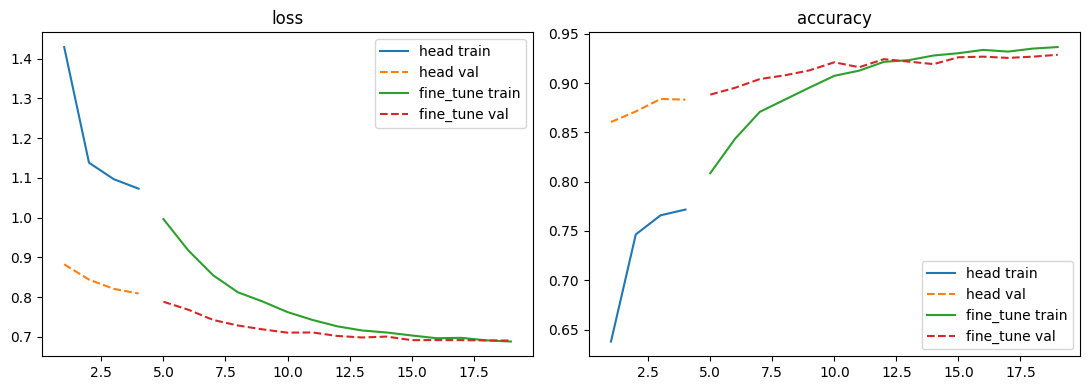

In [ ]:
model, base = build_model(BACKBONE, IMAGE_SIZE, len(classes))
loss = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

base.trainable = False
model.compile(optimizer=keras.optimizers.Adam(HEAD_LR), loss=loss, metrics=['accuracy'])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, class_weight=class_weight, verbose=1)

base.trainable = True
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
steps = len(train_ds) * FINE_EPOCHS
schedule = keras.optimizers.schedules.CosineDecay(FINE_LR / 10, decay_steps=steps, warmup_target=FINE_LR,
                                                  warmup_steps=len(train_ds))
model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.05), loss=loss, metrics=['accuracy'])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_EPOCHS, class_weight=class_weight, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
                          keras.callbacks.TerminateOnNaN()])
histories = {'head': h1.history, 'fine_tune': h2.history}

fig, axes = plt.subplots(1, 2, figsize=(11, 4)); off = 0
for ph, h in histories.items():
    e = np.arange(off + 1, off + len(h['loss']) + 1); off += len(h['loss'])
    for ax, k in zip(axes, ['loss', 'accuracy']):
        ax.plot(e, h[k], label=f'{ph} train'); ax.plot(e, h['val_' + k], '--', label=f'{ph} val'); ax.set_title(k); ax.legend()
plt.tight_layout(); plt.savefig(OUT / 'learning_curves.png', dpi=130); plt.show()

## 10. Export a float32 model (what the web app loads)

In [ ]:
keras.mixed_precision.set_global_policy('float32')
final, _ = build_model(BACKBONE, IMAGE_SIZE, len(classes), weights=None)
final.set_weights(model.get_weights())
x_chk = np.stack([load_like_app(p, IMAGE_SIZE) for p in k_val['file_path'][:16]])
diff = np.abs(final.predict(x_chk, verbose=0) - model.predict(x_chk, verbose=0)).max()
assert diff < 0.02, f'float32 copy differs too much: {diff}'
final.save(OUT / 'garbage_cnn.keras')
model = keras.models.load_model(OUT / 'garbage_cnn.keras')
print('Saved', OUT / 'garbage_cnn.keras', '| max diff vs training model:', round(float(diff), 5))

Saved /content/garbage_reallife_results/garbage_cnn.keras | max diff vs training model: 0.00046


## 11. Test: Kaggle test, web test, and our own photos

In [ ]:
eval_sets = {'kaggle_test': k_test, 'web_test': web_test, 'real_test': real_test}
eval_sets = {k: v.assign(label_id=v['label'].map(label_to_id)) for k, v in eval_sets.items() if len(v)}

models = {'new': (model, IMAGE_SIZE)}
if ORIGINAL_MODEL.exists():
    old = keras.models.load_model(ORIGINAL_MODEL)
    models['original'] = (old, tuple(old.input_shape[1:3]))
else:
    print('original_garbage_cnn.keras not uploaded -> no before/after comparison')

results, preds = [], {}
for mname, (m, size) in models.items():
    for sname, df in eval_sets.items():
        for tta in ([False, True] if mname == 'new' else [False]):
            p = predict_paths(m, df['file_path'].tolist(), size, tta=tta)
            y = df['label_id'].to_numpy()
            preds[(mname, sname, tta)] = p
            results.append({'model': mname + (' +flipTTA' if tta else ''), 'test_set': sname, 'images': len(df),
                            'accuracy': accuracy_score(y, p.argmax(1)),
                            'macro_f1': f1_score(y, p.argmax(1), average='macro')})
res = pd.DataFrame(results)
display(res.pivot(index='model', columns='test_set', values='accuracy').style.format('{:.1%}'))
display(res.pivot(index='model', columns='test_set', values='macro_f1').style.format('{:.3f}'))

original_garbage_cnn.keras not uploaded -> no before/after comparison


test_set,kaggle_test,web_test
model,,
new,93.8%,86.8%
new +flipTTA,94.0%,86.8%


test_set,kaggle_test,web_test
model,,
new,0.929,0.861
new +flipTTA,0.931,0.855


===== kaggle_test (new model)
              precision    recall  f1-score   support

     battery      0.939     0.959     0.949       145
  biological      0.976     0.952     0.964       126
   cardboard      0.939     0.957     0.948       324
     clothes      0.989     0.984     0.987       373
       glass      0.962     0.906     0.933       339
       metal      0.854     0.914     0.883       185
       paper      0.943     0.878     0.909       262
     plastic      0.898     0.915     0.906       317
       shoes      0.983     0.997     0.990       290
       trash      0.780     0.876     0.825        89

    accuracy                          0.938      2450
   macro avg      0.926     0.934     0.929      2450
weighted avg      0.940     0.938     0.939      2450

===== web_test (new model)
              precision    recall  f1-score   support

     battery      0.921     0.897     0.909        39
  biological      0.776     0.950     0.854        40
   cardboard      0.9

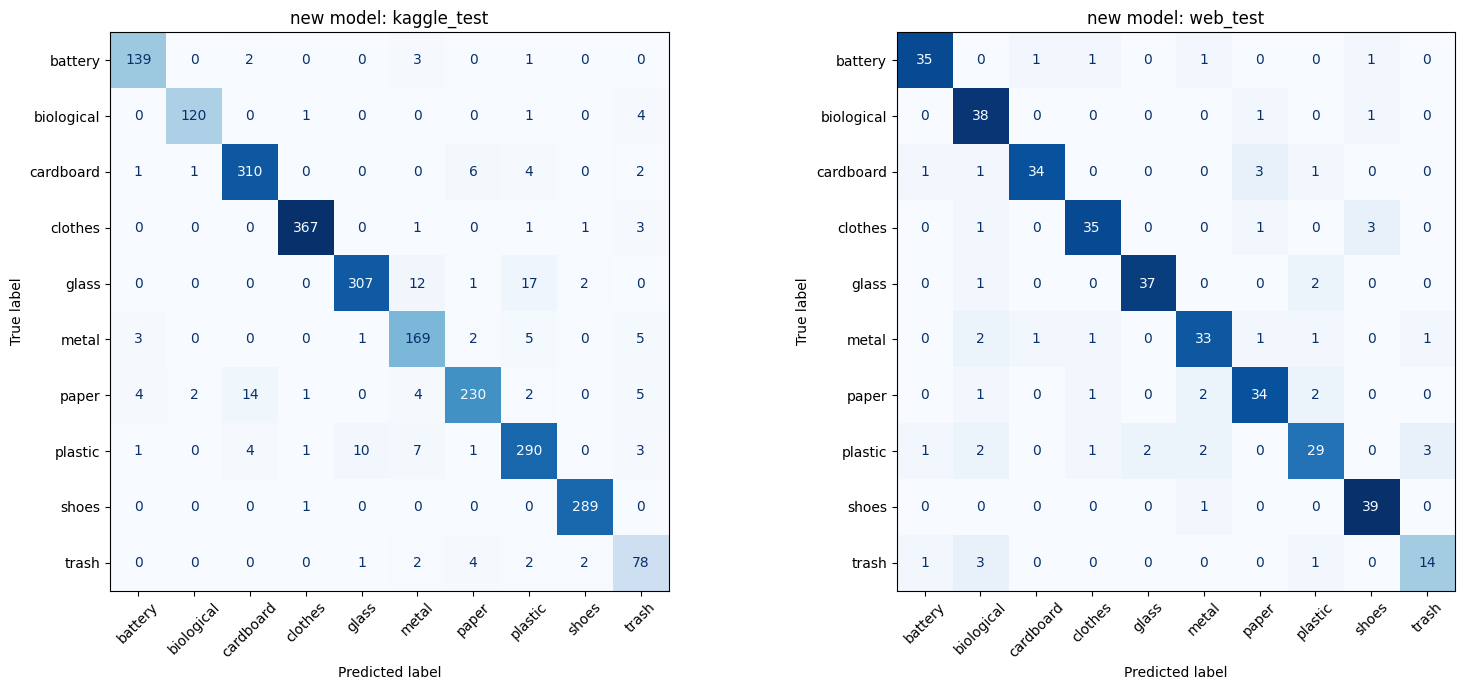

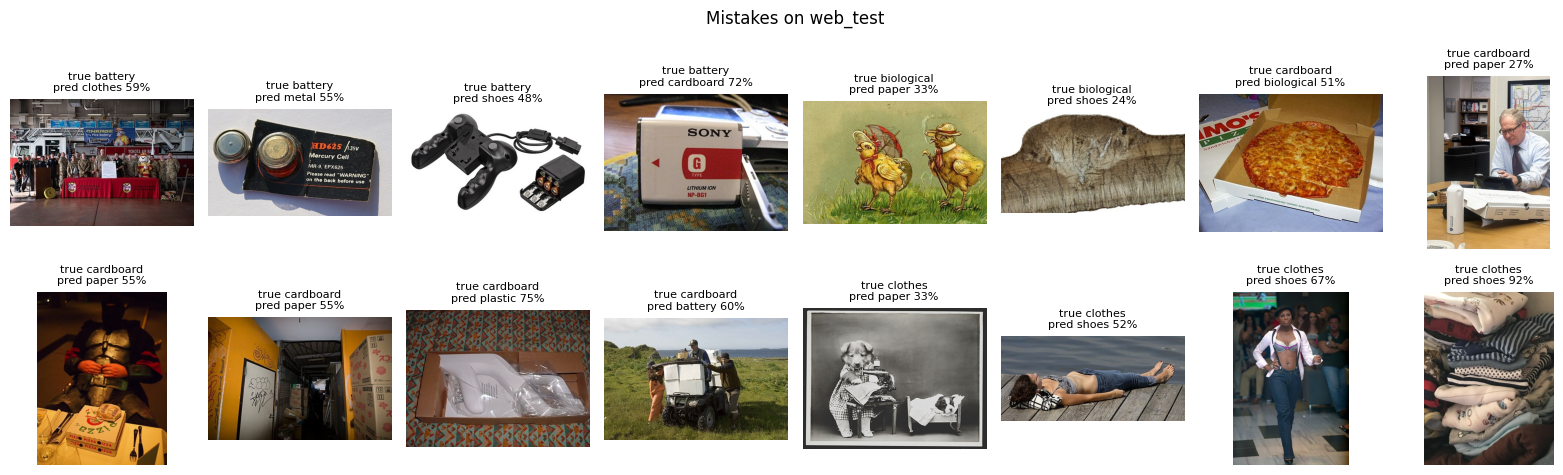

In [ ]:
# Per-class recall on the real-life sets + confusion matrices for the new model
for sname, df in eval_sets.items():
    y = df['label_id'].to_numpy()
    print(f'===== {sname} (new model)')
    print(classification_report(y, preds[('new', sname, False)].argmax(1), labels=range(len(classes)),
                                target_names=classes, digits=3, zero_division=0))
n = len(eval_sets)
fig, axes = plt.subplots(1, n, figsize=(8 * n, 7))
for ax, (sname, df) in zip(np.atleast_1d(axes), eval_sets.items()):
    ConfusionMatrixDisplay.from_predictions(df['label_id'], preds[('new', sname, False)].argmax(1),
        labels=range(len(classes)), display_labels=classes, xticks_rotation=45, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'new model: {sname}')
plt.tight_layout(); plt.savefig(OUT / 'confusion_matrices.png', dpi=120); plt.show()

# Mistakes on the most real-life set available
worst = 'real_test' if 'real_test' in eval_sets else 'web_test' if 'web_test' in eval_sets else 'kaggle_test'
df = eval_sets[worst]; p = preds[('new', worst, False)]
err = np.flatnonzero(p.argmax(1) != df['label_id'].to_numpy())[:16]
if len(err):
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
    for ax in axes.ravel(): ax.axis('off')
    for ax, i in zip(axes.ravel(), err):
        ax.imshow(to_rgb(Image.open(df.iloc[i]['file_path'])))
        ax.set_title(f"true {df.iloc[i]['label']}\npred {classes[p[i].argmax()]} {p[i].max():.0%}", fontsize=8)
    plt.suptitle(f'Mistakes on {worst}'); plt.tight_layout(); plt.savefig(OUT / 'mistakes.png', dpi=120); plt.show()

## 12. Calibrate confidence + choose a "not sure" threshold

In [ ]:
val_p = predict_paths(model, val_df['file_path'].tolist(), IMAGE_SIZE)
TEMPERATURE = fit_temperature(val_p, val_df['label_id'].to_numpy())
print('Temperature:', round(TEMPERATURE, 3), '(>1 means the raw model was over-confident)')
cov = pd.DataFrame(coverage_table(apply_temperature(preds[('new', worst, False)], TEMPERATURE),
                                  eval_sets[worst]['label_id'].to_numpy()))
print('On', worst); display(cov.style.format({'answered': '{:.0%}', 'accuracy_when_answered': '{:.1%}'}))

Temperature: 0.7 (>1 means the raw model was over-confident)
On web_test


,threshold,answered,accuracy_when_answered
0,0.000000,100%,86.8%
1,0.400000,96%,89.3%
2,0.500000,89%,91.4%
3,0.600000,85%,93.1%
4,0.700000,81%,95.1%
5,0.800000,75%,97.5%
6,0.900000,67%,98.4%


## 13. Save and download result

In [ ]:
config = {
    'dataset': DATASET, 'seed': SEED, 'backbone': BACKBONE, 'image_size': list(IMAGE_SIZE),
    'classes': classes, 'label_to_id': label_to_id, 'input_range': [0, 255],
    'preprocess': 'EXIF transpose -> RGB -> bilinear resize to image_size -> float32 0..255',
    'temperature': TEMPERATURE, 'max_per_class': MAX_PER_CLASS, 'near_dup_bits': NEAR_DUP_BITS,
    'split': 'StratifiedGroupKFold on dHash near-duplicate groups',
    'train_rows': len(train_df), 'val_rows': len(val_df), 'kaggle_test': len(k_test),
    'web_train': len(web_train), 'web_test': len(web_test), 'own_train': len(own_train), 'real_test': len(real_test),
    'head_epochs': HEAD_EPOCHS, 'fine_epochs_max': FINE_EPOCHS, 'fine_lr': FINE_LR, 'label_smoothing': LABEL_SMOOTHING,
    'class_weight': class_weight, 'kaggle_cleaning': {'enabled': CLEAN_KAGGLE, 'max_drop_frac': MAX_DROP_FRAC, 'outlier_frac': OUTLIER_FRAC}, 'zoom_out_p': ZOOM_OUT_P, 'background_photos': 0 if bg_bank is None else int(bg_bank.shape[0]),
    'versions': {'python': platform.python_version(), 'tensorflow': tf.__version__, 'keras': keras.__version__,
                 'numpy': np.__version__, 'pillow': PIL.__version__, 'sklearn': sklearn.__version__},
}
(OUT / 'config.json').write_text(json.dumps(config, indent=2))
(OUT / 'metrics.json').write_text(res.to_json(orient='records', indent=2))
(OUT / 'history.json').write_text(json.dumps(histories, indent=2, default=float))
cov.to_csv(OUT / 'confidence_threshold_table.csv', index=False)
for sname, df in eval_sets.items():
    p = apply_temperature(preds[('new', sname, False)], TEMPERATURE)
    pd.DataFrame({'file': [Path(f).name for f in df['file_path']], 'true': df['label'],
                  'pred': [classes[i] for i in p.argmax(1)], 'confidence': p.max(1)}).to_csv(OUT / f'pred_{sname}.csv', index=False)
if len(credits):
    credits.to_csv(OUT / 'web_image_credits.csv', index=False)
archive = shutil.make_archive('/content/garbage_reallife_results', 'zip', OUT)
print('Results ZIP:', archive)
try:
    from google.colab import files; files.download(archive)
except ImportError:
    pass

Results ZIP: /content/garbage_reallife_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>